In [1]:
from dotenv import load_dotenv
load_dotenv(".env", override=True)
%load_ext autoreload
%autoreload 2

# Deepagent for Research

We will use the `deepagents` package to create a research agent. When using the `deepagents` package, it's important to: 

1. Understand the native tools available
2. Supply task-specific tools
3. Supply task-specific instructions
4. Supply task-specific sub-agents

## Task-Specific Tools 

You can see an overview of the native tools in the [deepagents package README](https://github.com/langchain-ai/deepagents?tab=readme-ov-file#model) as well as the [quickstarts README](https://github.com/langchain-ai/deepagents-quickstarts). We'll extend this with two task-specific tools. 

### Search Tool 

There are different search tools that we can use. For example, we can use [Tavily](https://www.tavily.com/) to search for relevant URLs, then fetches the full webpage content.

### Think Tool 

We'll supply a [think tool](https://www.anthropic.com/engineering/claude-think-tool), which is a useful way to help audit agent decision making. 

In [2]:
from research_agent.tools import tavily_search, think_tool
tools = [tavily_search, think_tool]

## Task-Specific Instructions
 
Next, let's define task specific instructions using [a few prompting techniques for agents](https://youtu.be/XSZP9GhhuAc?si=zowpViL-2j-vI9hA):

### 1. Think Like The Agent
What instructions would you give a new work colleague?
- **Read the question carefully** - What specific information does the user need?
- **Start with broader searches** - Use broad, comprehensive queries first
- **After each search, pause and assess** - Do I have enough to answer? What's still missing?
- **Execute narrower searches as you gather information** - Fill in the gaps.

### 2. Concrete Heuristics (Prevent "Spin-Out" on excessive tool calls)
Use **Hard Limits** to prevent the research agent from calling tools excessively:
- **Stop when you can answer confidently** - Don't keep searching for perfection.
- **Give it budgets** - Use 2-3 search tool calls for simple queries. Use up to 5 for complex queries.
- **Limit** - Always stop after 5 search tool calls if you cannot find the right source(s).

### 3. Show your thinking
After each search tool calling, use [`think_tool` to analyze the results](https://www.anthropic.com/engineering/claude-think-tool):
- What key information did I find? 
- What's missing?
- Do I have enough to answer the question comprehensively?
- Should I search more or provide my answer?

In [3]:
from datetime import datetime
from utils import show_prompt, format_messages
from research_agent.prompts import (
    RESEARCHER_INSTRUCTIONS,
    RESEARCH_WORKFLOW_INSTRUCTIONS,
    SUBAGENT_DELEGATION_INSTRUCTIONS,
)

In [4]:
show_prompt(RESEARCHER_INSTRUCTIONS)

╭──────────────────────────────────────────────────── Prompt ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│  You are a research assistant conducting research on the user's input topic. For context, today's date is       │
│  {date}.                                                                                                        │
│                                                                                                                 │
│  <Task>                                                                                                         │
│  Your job is to use tools to gather information about the user's input topic.                                   │
│  You can use any of the research tools provided to you to find resources that can help answer the research      │
│  question.                                                                                                      │
│  You can call these tools in series or in parallel, your research is conducted in a tool-calling loop.          │
│  </Task>                                                                                                        │
│                                                                                                                 │
│  <Available Research Tools>                                                                                     │
│  You have access to two specific research tools:                                                                │
│  1. **tavily_search**: For conducting web searches to gather information                                        │
│  2. **think_tool**: For reflection and strategic planning during research                                       │
│  **CRITICAL: Use think_tool after each search to reflect on results and plan next steps**                       │
│  </Available Research Tools>                                                                                    │
│                                                                                                                 │
│  <Instructions>                                                                                                 │
│  Think like a human researcher with limited time. Follow these steps:                                           │
│                                                                                                                 │
│  1. **Read the question carefully** - What specific information does the user need?                             │
│  2. **Start with broader searches** - Use broad, comprehensive queries first                                    │
│  3. **After each search, pause and assess** - Do I have enough to answer? What's still missing?                 │
│  4. **Execute narrower searches as you gather information** - Fill in the gaps                                  │
│  5. **Stop when you can answer confidently** - Don't keep searching for perfection                              │
│  </Instructions>                                                                                                │
│                                                                                                                 │
│  <Hard Limits>                                                                                                  │
│  **Tool Call Budgets** (Prevent excessive searching):                                                           │
│  - **Simple queries**: Use 2-3 search tool calls maximum                                                        │
│  - **Complex queries**: Use up to 5 search tool calls maximum                                                   │
│  - **Always stop**: After 5 search tool calls if you cannot find the right sources                              │
│                                                       

## Task-Specific Sub-Agents

You can specify [custom subagents](https://github.com/langchain-ai/deepagents?tab=readme-ov-file#subagents) as a means of context isolation. 

Here's well define a sub-agent that can search the web for information. 

In [5]:
# Get current date
current_date = datetime.now().strftime("%Y-%m-%d")

# Create research sub-agent
research_sub_agent = {
    "name": "research-agent",
    "description": "Delegate research to the sub-agent researcher. Only give this researcher one topic at a time.",
    "system_prompt": RESEARCHER_INSTRUCTIONS.format(date=current_date),
    "tools": [tavily_search, think_tool],
}

## Putting it all together

### Instructions

Now, we can look at all of our instructions together. 

In [6]:
# Limits
max_concurrent_research_units = 3
max_researcher_iterations = 3

# Combine orchestrator instructions (RESEARCHER_INSTRUCTIONS only for sub-agents)
INSTRUCTIONS = (
    RESEARCH_WORKFLOW_INSTRUCTIONS
    + "\n\n"
    + "=" * 80
    + "\n\n"
    +  SUBAGENT_DELEGATION_INSTRUCTIONS.format(
        max_concurrent_research_units=max_concurrent_research_units,
        max_researcher_iterations=max_researcher_iterations,
    )
)

show_prompt(INSTRUCTIONS)

╭──────────────────────────────────────────────────── Prompt ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│  # Research Workflow                                                                                            │
│                                                                                                                 │
│  Follow this workflow for all research requests:                                                                │
│                                                                                                                 │
│  1. **Plan**: Create a todo list with write_todos to break down the research into focused tasks                 │
│  2. **Save the request**: Use write_file() to save the user's research question to `/research_request.md`       │
│  3. **Research**: Delegate research tasks to sub-agents using the task() tool - ALWAYS use sub-agents for       │
│  research, never conduct research yourself                                                                      │
│  4. **Synthesize**: Review all sub-agent findings and consolidate citations (each unique URL gets one number    │
│  across all findings)                                                                                           │
│  5. **Write Report**: Write a comprehensive final report to `/final_report.md` (see Report Writing Guidelines   │
│  below)                                                                                                         │
│  6. **Verify**: Read `/research_request.md` and confirm you've addressed all aspects with proper citations and  │
│  structure                                                                                                      │
│                                                                                                                 │
│  ## Research Planning Guidelines                                                                                │
│  - Batch similar research tasks into a single TODO to minimize overhead                                         │
│  - For simple fact-finding questions, use 1 sub-agent                                                           │
│  - For comparisons or multi-faceted topics, delegate to multiple parallel sub-agents                            │
│  - Each sub-agent should research one specific aspect and return findings                                       │
│                                                                                                                 │
│  ## Report Writing Guidelines                                                                                   │
│                                                                                                                 │
│  When writing the final report to `/final_report.md`, follow these structure patterns:                          │
│                                                                                                                 │
│  **For comparisons:**                                                                                           │
│  1. Introduction                                                                                                │
│  2. Overview of topic A                                                                                         │
│  3. Overview of topic B                                                                                         │
│  4. Detailed comparison                                                                                         │
│  5. Conclusion                                                                                                  │
│                                                                                                                 │
│  **For lists/rankings:**                              

### Create the agent

Now, we create our deepagent with these components. 

In [7]:
from IPython.display import Image, display
from deepagents import create_deep_agent
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_openrouter import ChatOpenRouter

# Model Gemini 3 
# model = ChatGoogleGenerativeAI(model="gemini-3-pro-preview")

# Model OpenRouter (DeepSeek V4.1 Flash)
model = ChatOpenRouter(model="deepseek/deepseek-v4.1-flash", temperature=0.0)

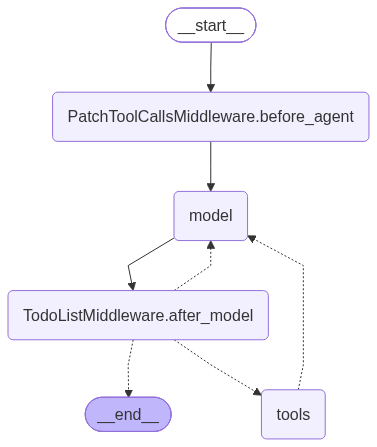

In [8]:
# Create the agent
agent = create_deep_agent(
      model=model,
      tools=tools, 
      system_prompt=INSTRUCTIONS,
      subagents=[research_sub_agent],
  )
  
# Show the agent
display(Image(agent.get_graph().draw_mermaid_png()))

In [10]:
result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "research context engineering approaches used to build AI agents",
            }
        ],
    }, 
)
format_messages(result["messages"])

╭─────────────────────────────────────────────────── 🧑 Human ────────────────────────────────────────────────────╮
│ research context engineering approaches used to build AI agents                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: write_todos                                                                                       │
│    Args: {                                                                                                      │
│   "todos": [                                                                                                    │
│     {                                                                                                           │
│       "content": "Save research request to /research_request.md",                                               │
│       "status": "in_progress"                                                                                   │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Delegate research on context engineering approaches for AI agents to sub-agents",             │
│       "status": "pending"                                                                                       │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Synthesize findings and consolidate citations",                                               │
│       "status": "pending"                                                                                       │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Write comprehensive final report to /final_report.md",                                        │
│       "status": "pending"                                                                                       │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Verify report addresses all aspects of the request",                                          │
│       "status": "pending"                                                                                       │
│     }                                                                                                           │
│   ]                                                                                                             │
│ }                                                                                                               │
│    ID: call_16ba6e0feb4d4d4abba27542                                                                            │
│                                                                                                                 │
│ 🔧 Tool Call: write_file                                                                                        │
│    Args: {                                                                                                      │
│   "file_path": "/research_request.md",                                                                          │
│   "content": "# Research Request\n\n## Question\nResearch context engineering approaches used to build AI       │
│ agents.\n\n## Scope\n- What \"context engineering\" means

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated todo list to [{'content': 'Save research request to /research_request.md', 'status': 'in_progress'},    │
│ {'content': 'Delegate research on context engineering approaches for AI agents to sub-agents', 'status':        │
│ 'pending'}, {'content': 'Synthesize findings and consolidate citations', 'status': 'pending'}, {'content':      │
│ 'Write comprehensive final report to /final_report.md', 'status': 'pending'}, {'content': 'Verify report        │
│ addresses all aspects of the request', 'status': 'pending'}]                                                    │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated file /research_request.md                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: write_todos                                                                                       │
│    Args: {                                                                                                      │
│   "todos": [                                                                                                    │
│     {                                                                                                           │
│       "content": "Save research request to /research_request.md",                                               │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Delegate research on context engineering approaches for AI agents to sub-agents",             │
│       "status": "in_progress"                                                                                   │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Synthesize findings and consolidate citations",                                               │
│       "status": "pending"                                                                                       │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Write comprehensive final report to /final_report.md",                                        │
│       "status": "pending"                                                                                       │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Verify report addresses all aspects of the request",                                          │
│       "status": "pending"                                                                                       │
│     }                                                                                                           │
│   ]                                                                                                             │
│ }                                                                                                               │
│    ID: call_6c7e885fda9b4b1aa5fe2788                                                                            │
│                                                                                                                 │
│ 🔧 Tool Call: task                                                                                              │
│    Args: {                                                                                                      │
│   "description": "Research the foundational concepts and core techniques of \"context engineering\" for         │
│ building AI agents. I need a comprehensive, well-cited overview covering:\n\n1. Definition and origin of the    │
│ term \"context engineering\" \u2014 how it is defined by 

...

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│      1  # Research Request                                                                                      │
│      2                                                                                                          │
│      3  ## Question                                                                                             │
│      4  Research context engineering approaches used to build AI agents.                                        │
│      5                                                                                                          │
│      6  ## Scope                                                                                                │
│      7  - What "context engineering" means in the context of AI agents                                          │
│      8  - Core techniques and strategies (e.g., context assembly, retrieval, memory, compression,               │
│ summarization, tool/observation management)                                                                     │
│      9  - Frameworks, patterns, and best practices                                                              │
│     10  - How it relates to prompt engineering and RAG                                                          │
│     11  - Practical implementations and industry approaches                                                     │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated todo list to [{'content': 'Save research request to /research_request.md', 'status': 'completed'},      │
│ {'content': 'Delegate research on context engineering approaches for AI agents to sub-agents', 'status':        │
│ 'completed'}, {'content': 'Synthesize findings and consolidate citations', 'status': 'completed'}, {'content':  │
│ 'Write comprehensive final report to /final_report.md', 'status': 'completed'}, {'content': 'Verify report      │
│ addresses all aspects of the request', 'status': 'in_progress'}]                                                │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: write_todos                                                                                       │
│    Args: {                                                                                                      │
│   "todos": [                                                                                                    │
│     {                                                                                                           │
│       "content": "Save research request to /research_request.md",                                               │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Delegate research on context engineering approaches for AI agents to sub-agents",             │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Synthesize findings and consolidate citations",                                               │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Write comprehensive final report to /final_report.md",                                        │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "Verify report addresses all aspects of the request",                                          │
│       "status": "completed"                                                                                     │
│     }                                                                                                           │
│   ]                                                                                                             │
│ }                                                                                                               │
│    ID: call_251ea64f475f4cf09ebb37d0                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated todo list to [{'content': 'Save research request to /research_request.md', 'status': 'completed'},      │
│ {'content': 'Delegate research on context engineering approaches for AI agents to sub-agents', 'status':        │
│ 'completed'}, {'content': 'Synthesize findings and consolidate citations', 'status': 'completed'}, {'content':  │
│ 'Write comprehensive final report to /final_report.md', 'status': 'completed'}, {'content': 'Verify report      │
│ addresses all aspects of the request', 'status': 'completed'}]                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ The report is complete at `/final_report.md`. Here's a summary of what it covers.                               │
│                                                                                                                 │
│ ## Context Engineering for AI Agents                                                                            │
│                                                                                                                 │
│ **Definition.** Context engineering is the discipline of designing the full information environment an LLM      │
│ receives at each step — system instructions, retrieved knowledge, tool results, and conversation history —      │
│ assembled dynamically at runtime. Karpathy's framing: "filling the context window with just the right           │
│ information for the next step." It subsumes prompt engineering, which covers only the system-instruction        │
│ component.                                                                                                      │
│                                                                                                                 │
│ **Why it matters.** Most agent failures are context failures, not model failures. The context window is a       │
│ finite "attention budget," and models degrade with length ("context rot" — Chroma's study of 18 models across   │
│ 194,480 calls found reliability drops even on simple retrieval, with effective context at ~50–65% of            │
│ advertised). Four failure modes: poisoning, distraction, confusion, clash.                                      │
│                                                                                                                 │
│ **Core techniques** (organized via LangChain's **Write / Select / Compress / Isolate** framework):              │
│ - **Context assembly** — system prompts at the "right altitude," minimal non-overlapping tools, curated         │
│ few-shot examples                                                                                               │
│ - **Retrieval & just-in-time loading** — lightweight identifiers, progressive disclosure, dynamic tool          │
│ selection (3x accuracy gain)                                                                                    │
│ - **Memory systems** — short-term vs. long-term, vector/fact-extraction/static memory blocks                    │
│ - **Compression & compaction** — rolling summaries, tool-result clearing, auto-compaction (up to 80% token      │
│ reduction)                                                                                                      │
│ - **Tool/observation management** — token-efficient tools, tool masking, KV-cache-stable prefixes               │
│ - **Sub-agent isolation** — clean scoped contexts (Anthropic reports 90.2% higher success on complex research)  │
│                                                                                                                 │
│ **Frameworks & industry approaches.** Detailed guidance from Anthropic (compaction, note-taking, sub-agents),   │
│ OpenAI (Agents SDK `Session`, trimming/summarization), LangChain/LangGraph, LlamaIndex, and Manus (KV-cache     │
│ optimization, tool masking). Notable debate: Anthropic's multi-agent gains vs. Cognition's "Don't Build         │
│ Multi-Agents" single-agent argument.                                                                            │
│                                                                                                                 │
│ **Gaps flagged:** Google/DeepMind and frameworks like CrewAI/AutoGen/DSPy/Haystack have comparatively thin      │
│ public documentation on context-engineering primitives.                                                         │
│                                                        

In [11]:
from deepagents.backends.utils import file_data_to_string

# Convert a specific file to string
file_content = file_data_to_string(result["files"]['/final_report.md'])
show_prompt(file_content) 

╭──────────────────────────────────────────────────── Prompt ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│  # Context Engineering for AI Agents: Approaches, Techniques, and Practices                                     │
│                                                                                                                 │
│  ## 1. Overview: What Context Engineering Is                                                                    │
│                                                                                                                 │
│  Context engineering is the discipline of designing and orchestrating the *full information environment* an     │
│  LLM receives at each step of a task — system instructions, retrieved knowledge, tool results, conversation     │
│  history, and any other relevant state — rather than merely crafting a single prompt. It treats the context     │
│  window as a dynamic, programmable interface that is assembled at runtime, not a static text box written once   │
│  [1][21].                                                                                                       │
│                                                                                                                 │
│  The term was popularized in mid-2025 by Andrej Karpathy, who defined it as "the delicate art and science of    │
│  filling the context window with just the right information for the next step" [2]. He observed that in every   │
│  industrial-strength LLM application this goes far beyond prompting: it includes task descriptions, few-shot    │
│  examples, RAG results, multimodal data, tool definitions, state, and history, and getting the balance right    │
│  is non-trivial — too little context and the model lacks information; too much and costs rise while             │
│  performance degrades [2][21]. Shopify CEO Tobi Lutke endorsed the framing as "the art of providing all the     │
│  context for the task to be plausibly solvable by the LLM" [3], and Simon Willison noted that unlike "prompt    │
│  engineering," the term "context engineering" has an inferred definition much closer to the actual work         │
│  involved [4].                                                                                                  │
│                                                                                                                 │
│  Anthropic frames it as the natural successor to prompt engineering: "the set of strategies for curating and    │
│  maintaining the optimal set of tokens (information) during LLM inference" [1]. The central constraint is that  │
│  context is a **finite resource with diminishing marginal returns**. Because transformers create n² pairwise    │
│  attention relationships, models have a limited "attention budget," and the guiding principle across the field  │
│  is to *find the smallest set of high-signal tokens that maximize the likelihood of the desired outcome* [1].   │
│                                                                                                                 │
│  ### Relationship to prompt engineering                                                                         │
│                                                                                                                 │
│  Prompt engineering is a **subset** of context engineering, not a separate practice [1][21]. Prompt             │
│  engineering asks *"What words should I use?"*; context engineering asks *"What configuration of context is     │
│  most likely to generate the desired behavior?"* [20]. The four components of an LLM's context at any step are  │
│  **system instructions** (the prompt itself, behavioral rules, output format), **retrieved knowledge**          │
│  (documents/code/data via RAG or search), **tool resul

Trace: 

https://smith.langchain.com/public/72d23852-4616-4bcc-8d8a-b0d1905c945b/r